
# پروژه تحلیل داده و آمار توصیفی مشتریان
## Customer Data Analysis & Exploratory Data Analysis

**هدف:** بررسی ویژگی‌های مشتریان، تحلیل الگوهای خرید، محاسبه شاخص‌های آماری و ارائه نمودارهای کاربردی برای تصمیم‌گیری کسب‌وکار.

**کتابخانه‌ها:** Pandas، NumPy، Matplotlib و Seaborn


In [1]:


import os
import zipfile

مسیر_فایل = r"C:\Users\EMTOO\Downloads\online+retail.zip"

if os.path.exists(مسیر_فایل):
    print("فایل دیتاست پیدا شد.")

    with zipfile.ZipFile(مسیر_فایل, "r") as فایل_فشرده:
        print("\nفایل‌های موجود داخل ZIP:")
        for نام in فایل_فشرده.namelist():
            print(نام)
else:
    print("فایل پیدا نشد؛ مسیر را بررسی کن.")


فایل دیتاست پیدا شد.

فایل‌های موجود داخل ZIP:
Online Retail.xlsx


In [2]:

# ==========================================
# سلول ۲: خواندن دیتاست از داخل ZIP
# ==========================================

import pandas as pd
import zipfile
import io

with zipfile.ZipFile(مسیر_فایل, "r") as فایل_فشرده:
    فایلهای_اکسل = [
        نام for نام in فایل_فشرده.namelist()
        if نام.lower().endswith((".xlsx", ".xls"))
    ]

    if not فایلهای_اکسل:
        print("فایل اکسل داخل ZIP پیدا نشد.")
    else:
        نام_اکسل = فایلهای_اکسل[0]

        with فایل_فشرده.open(نام_اکسل) as فایل:
            فروش = pd.read_excel(io.BytesIO(فایل.read()))

        print("نام فایل:", نام_اکسل)
        print("ابعاد دیتاست:", فروش.shape)

        display(فروش.head())


نام فایل: Online Retail.xlsx
ابعاد دیتاست: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:

# ==========================================
# سلول ۳: بررسی ساختار و کیفیت اولیه داده‌ها
# ==========================================

print("=" * 55)
print("گزارش اولیه دیتاست فروش آنلاین")
print("=" * 55)

print(f"تعداد رکوردها: {فروش.shape[0]:,}")
print(f"تعداد ستون‌ها: {فروش.shape[1]}")

print("\nنام ستون‌ها:")
print(فروش.columns.tolist())

print("\nاطلاعات ستون‌ها:")
فروش.info()

print("\nپنج رکورد اول:")
display(فروش.head())

print("\nپنج رکورد آخر:")
display(فروش.tail())

print("\nتعداد مقادیر گمشده هر ستون:")
display(
    فروش.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame("تعداد مقادیر گمشده")
)

print("\nدرصد مقادیر گمشده:")
درصد_گمشده = (
    فروش.isnull().mean().mul(100)
    .sort_values(ascending=False)
    .round(2)
)
display(درصد_گمشده.to_frame("درصد گمشده"))


گزارش اولیه دیتاست فروش آنلاین
تعداد رکوردها: 541,909
تعداد ستون‌ها: 8

نام ستون‌ها:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

اطلاعات ستون‌ها:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

پنج رکورد اول:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



پنج رکورد آخر:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France



تعداد مقادیر گمشده هر ستون:


,تعداد مقادیر گمشده
CustomerID,135080
Description,1454
InvoiceNo,0
StockCode,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0



درصد مقادیر گمشده:


,درصد گمشده
CustomerID,24.93
Description,0.27
InvoiceNo,0.00
StockCode,0.00
Quantity,0.00
InvoiceDate,0.00
UnitPrice,0.00
Country,0.00


In [4]:

# ==========================================
# سلول ۴: ارزیابی کیفیت داده‌ها
# ==========================================

print("تعداد ردیف‌های کاملاً تکراری:")
print(f"{فروش.duplicated().sum():,}")

print("\nتعداد فاکتورهای لغوشده:")
print(
    فروش["InvoiceNo"].astype(str)
    .str.startswith("C")
    .sum()
)

print("\nتعداد مقادیر غیرمثبت در تعداد کالا:")
print((فروش["Quantity"] <= 0).sum())

print("\nتعداد قیمت‌های غیرمثبت:")
print((فروش["UnitPrice"] <= 0).sum())

print("\nتعداد شناسه‌های مشتری گمشده:")
print(فروش["CustomerID"].isna().sum())

print("\nآمار توصیفی متغیرهای عددی:")
display(فروش.describe().T.round(2))


تعداد ردیف‌های کاملاً تکراری:
5,268

تعداد فاکتورهای لغوشده:
9288

تعداد مقادیر غیرمثبت در تعداد کالا:
10624

تعداد قیمت‌های غیرمثبت:
2517

تعداد شناسه‌های مشتری گمشده:
135080

آمار توصیفی متغیرهای عددی:


,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303


In [5]:

# ==========================================
# سلول ۵: پاک‌سازی داده‌ها برای تحلیل فروش
# ==========================================

فروش_پاک = فروش.copy()

# اصلاح نوع داده تاریخ
فروش_پاک["InvoiceDate"] = pd.to_datetime(
    فروش_پاک["InvoiceDate"],
    errors="coerce"
)

# حذف ردیف‌های کاملاً تکراری
تعداد_تکراری = فروش_پاک.duplicated().sum()
فروش_پاک = فروش_پاک.drop_duplicates().copy()

# حذف فاکتورهای لغوشده
فاکتور_معتبر = ~فروش_پاک["InvoiceNo"].astype(str).str.startswith("C")

# انتخاب ردیف‌های دارای تعداد و قیمت مثبت و تاریخ معتبر
شرط_فروش = (
    فاکتور_معتبر
    & (فروش_پاک["Quantity"] > 0)
    & (فروش_پاک["UnitPrice"] > 0)
    & فروش_پاک["InvoiceDate"].notna()
)

فروش_پاک = فروش_پاک.loc[شرط_فروش].copy()

# محاسبه مبلغ هر ردیف
فروش_پاک["SalesAmount"] = (
    فروش_پاک["Quantity"] * فروش_پاک["UnitPrice"]
)

print("گزارش پاک‌سازی")
print("-" * 40)
print(f"تعداد ردیف‌های تکراری حذف‌شده: {تعداد_تکراری:,}")
print(f"تعداد رکوردهای باقی‌مانده: {len(فروش_پاک):,}")
print(f"تعداد رکوردهای حذف‌شده: {len(فروش) - len(فروش_پاک):,}")
print(f"تعداد مشتریان دارای شناسه: {فروش_پاک['CustomerID'].nunique():,}")
print(f"تعداد شناسه‌های مشتری گمشده: {فروش_پاک['CustomerID'].isna().sum():,}")

display(فروش_پاک.head())


گزارش پاک‌سازی
----------------------------------------
تعداد ردیف‌های تکراری حذف‌شده: 5,268
تعداد رکوردهای باقی‌مانده: 524,878
تعداد رکوردهای حذف‌شده: 17,031
تعداد مشتریان دارای شناسه: 4,338
تعداد شناسه‌های مشتری گمشده: 132,186


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [6]:

# ==========================================
# سلول ۶: تحلیل آماری مبلغ فروش
# ==========================================

متغیر_فروش = فروش_پاک["SalesAmount"]

شاخصهای_فروش = pd.Series({
    "تعداد رکوردها": متغیر_فروش.count(),
    "مجموع مبلغ ردیف‌های فروش": متغیر_فروش.sum(),
    "میانگین مبلغ هر ردیف": متغیر_فروش.mean(),
    "میانه مبلغ هر ردیف": متغیر_فروش.median(),
    "انحراف معیار": متغیر_فروش.std(),
    "واریانس": متغیر_فروش.var(),
    "حداقل مبلغ": متغیر_فروش.min(),
    "چارک اول": متغیر_فروش.quantile(0.25),
    "چارک دوم (میانه)": متغیر_فروش.quantile(0.50),
    "چارک سوم": متغیر_فروش.quantile(0.75),
    "صدک ۹۰": متغیر_فروش.quantile(0.90),
    "صدک ۹۵": متغیر_فروش.quantile(0.95),
    "حداکثر مبلغ": متغیر_فروش.max(),
    "چولگی": متغیر_فروش.skew(),
    "کشیدگی اضافی": متغیر_فروش.kurt()
})

display(شاخصهای_فروش.to_frame("مقدار").round(2))


,مقدار
تعداد رکوردها,524878.00
مجموع مبلغ ردیف‌های فروش,10642110.80
میانگین مبلغ هر ردیف,20.28
میانه مبلغ هر ردیف,9.92
انحراف معیار,271.69
واریانس,73817.39
حداقل مبلغ,0.00
چارک اول,3.90
چارک دوم (میانه),9.92
چارک سوم,17.70


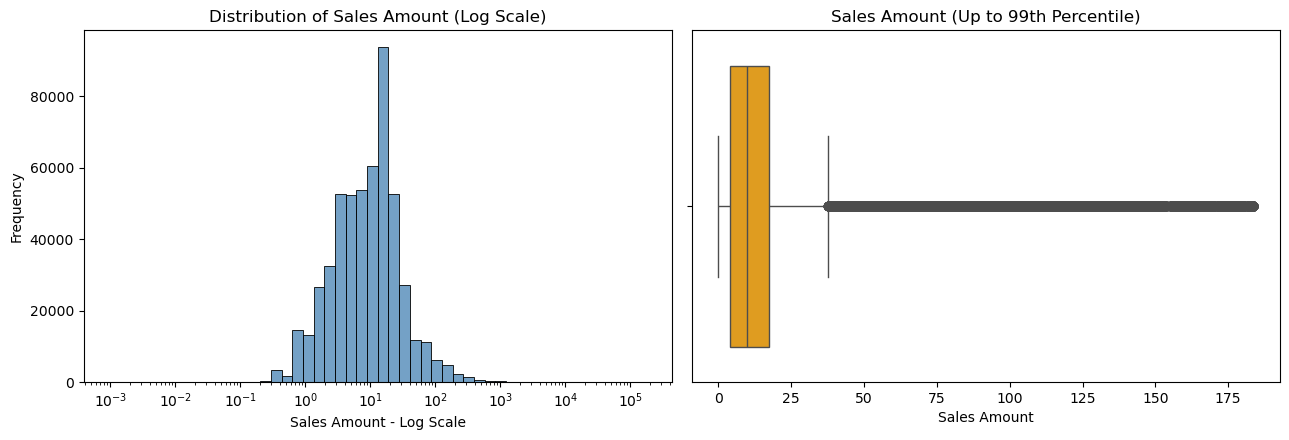

In [9]:

# ==========================================
# سلول ۷: نمایش حرفه‌ای توزیع مبلغ فروش
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# نمودار توزیع با مقیاس لگاریتمی
sns.histplot(
    x=فروش_پاک["SalesAmount"],
    bins=50,
    log_scale=True,
    ax=axes[0],
    color="steelblue"
)
axes[0].set_title("Distribution of Sales Amount (Log Scale)")
axes[0].set_xlabel("Sales Amount - Log Scale")
axes[0].set_ylabel("Frequency")

# نمودار جعبه‌ای تا صدک ۹۹
حد_نمایش = فروش_پاک["SalesAmount"].quantile(0.99)

sns.boxplot(
    x=فروش_پاک.loc[
        فروش_پاک["SalesAmount"] <= حد_نمایش,
        "SalesAmount"
    ],
    ax=axes[1],
    color="orange"
)
axes[1].set_title("Sales Amount (Up to 99th Percentile)")
axes[1].set_xlabel("Sales Amount")

plt.tight_layout()
plt.show()


In [10]:

# ==========================================
# سلول ۸: شناسایی مقادیر پرت بالقوه
# ==========================================

Q1 = فروش_پاک["SalesAmount"].quantile(0.25)
Q3 = فروش_پاک["SalesAmount"].quantile(0.75)

IQR = Q3 - Q1

حد_پایین = Q1 - 1.5 * IQR
حد_بالا = Q3 + 1.5 * IQR

فروش_پرت = فروش_پاک.loc[
    (فروش_پاک["SalesAmount"] < حد_پایین)
    | (فروش_پاک["SalesAmount"] > حد_بالا)
].copy()

print(f"چارک اول: {Q1:.2f}")
print(f"چارک سوم: {Q3:.2f}")
print(f"دامنه بین چارکی: {IQR:.2f}")
print(f"حد پایین: {حد_پایین:.2f}")
print(f"حد بالا: {حد_بالا:.2f}")
print(f"تعداد مقادیر پرت بالقوه: {len(فروش_پرت):,}")
print(
    f"درصد مقادیر پرت بالقوه: "
    f"{len(فروش_پرت) / len(فروش_پاک) * 100:.2f}%"
)

display(
    فروش_پرت[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "SalesAmount"]
    ].sort_values("SalesAmount", ascending=False).head(10)
)


چارک اول: 3.90
چارک سوم: 17.70
دامنه بین چارکی: 13.80
حد پایین: -16.80
حد بالا: 38.40
تعداد مقادیر پرت بالقوه: 42,624
درصد مقادیر پرت بالقوه: 8.12%


,InvoiceNo,StockCode,Quantity,UnitPrice,SalesAmount
540421,581483,23843,80995,2.08,168469.60
61619,541431,23166,74215,1.04,77183.60
222680,556444,22502,60,649.50,38970.00
15017,537632,AMAZONFEE,1,13541.33,13541.33
299982,A563185,B,1,11062.06,11062.06
173382,551697,POST,1,8142.75,8142.75
348325,567423,23243,1412,5.06,7144.72
160546,550461,21108,3114,2.10,6539.40
52711,540815,21108,3114,2.10,6539.40
421601,573003,23084,2400,2.08,4992.00


,Month,مبلغ_فروش,تعداد_ردیف_فروش,تعداد_فاکتور,تعداد_مشتری
0,2010-12,821452.73,40991,1559,885
1,2011-01,689811.61,34060,1086,741
2,2011-02,522545.56,26882,1100,758
3,2011-03,716215.26,35497,1454,974
4,2011-04,536968.49,28882,1246,856
5,2011-05,769296.61,35917,1681,1056
6,2011-06,760547.01,35716,1533,991
7,2011-07,718076.12,38395,1475,949
8,2011-08,757841.38,34264,1361,935
9,2011-09,1056435.19,48900,1837,1266


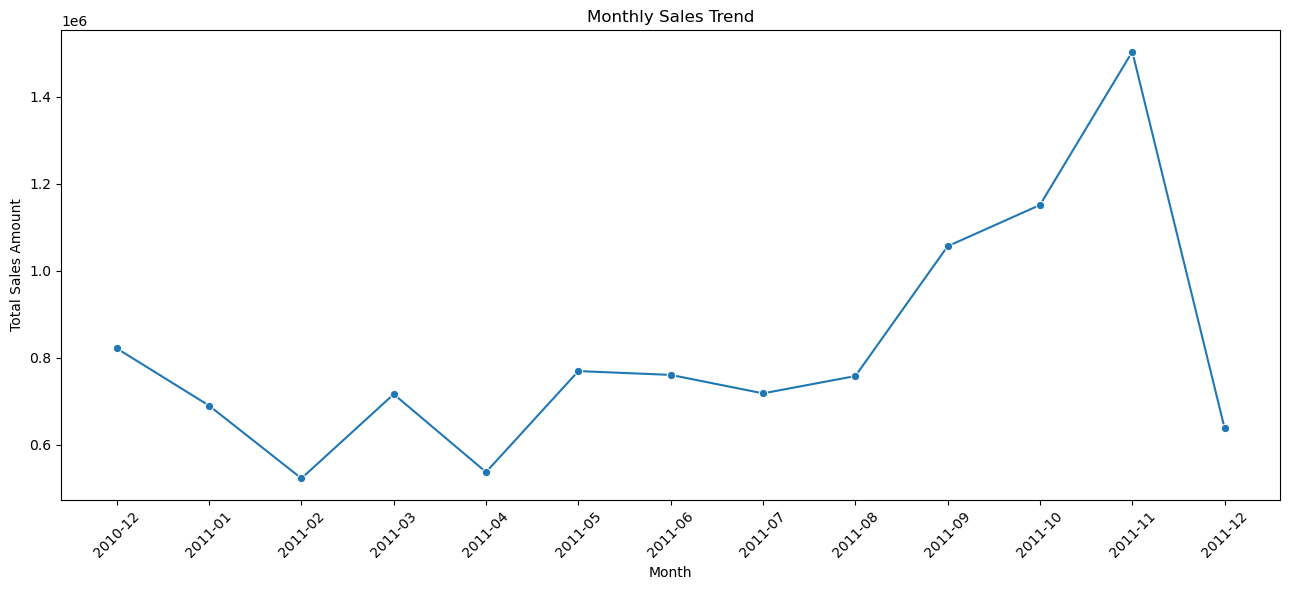

In [11]:

# ==========================================
# سلول ۹: تحلیل فروش ماهانه
# ==========================================

فروش_پاک["Month"] = (
    فروش_پاک["InvoiceDate"].dt.to_period("M").astype(str)
)

فروش_ماهانه = (
    فروش_پاک.groupby("Month")
    .agg(
        مبلغ_فروش=("SalesAmount", "sum"),
        تعداد_ردیف_فروش=("InvoiceNo", "size"),
        تعداد_فاکتور=("InvoiceNo", "nunique"),
        تعداد_مشتری=("CustomerID", "nunique")
    )
    .reset_index()
)

display(فروش_ماهانه.round(2))

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=فروش_ماهانه,
    x="Month",
    y="مبلغ_فروش",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,DayOfWeek,مبلغ_فروش,تعداد_فاکتور,نام_روز
5,6,806790.78,2204,Sunday
0,0,1775782.07,3126,Monday
1,1,2175700.51,3554,Tuesday
2,2,1847074.38,3690,Wednesday
3,3,2199292.57,4246,Thursday
4,4,1837470.49,3140,Friday


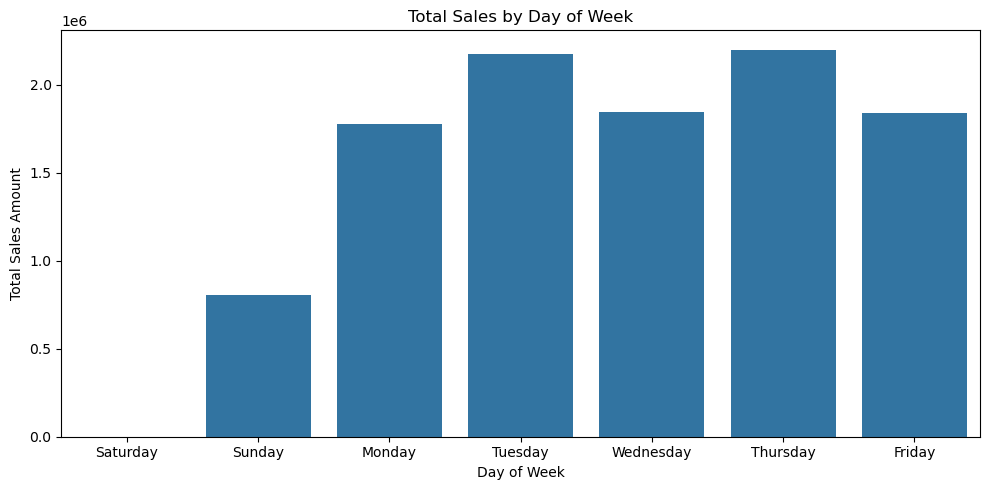

In [13]:

# ==========================================
# تحلیل فروش بر اساس روز هفته
# ==========================================

نام_روزها = {
    5: "Saturday",
    6: "Sunday",
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday"
}

ترتیب_روزها = [
    "Saturday", "Sunday", "Monday",
    "Tuesday", "Wednesday", "Thursday", "Friday"
]

فروش_پاک["DayOfWeek"] = فروش_پاک["InvoiceDate"].dt.dayofweek

فروش_روزانه = (
    فروش_پاک.groupby("DayOfWeek")
    .agg(
        مبلغ_فروش=("SalesAmount", "sum"),
        تعداد_فاکتور=("InvoiceNo", "nunique")
    )
    .reset_index()
)

فروش_روزانه["نام_روز"] = فروش_روزانه["DayOfWeek"].map(نام_روزها)
فروش_روزانه["نام_روز"] = pd.Categorical(
    فروش_روزانه["نام_روز"],
    categories=ترتیب_روزها,
    ordered=True
)

فروش_روزانه = فروش_روزانه.sort_values("نام_روز")

display(فروش_روزانه.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(data=فروش_روزانه, x="نام_روز", y="مبلغ_فروش")

plt.title("Total Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Sales Amount")
plt.tight_layout()
plt.show()


۱۰ کشور برتر از نظر مجموع مبلغ فروش:


,مبلغ_فروش,تعداد_فاکتور,تعداد_مشتری
Country,,,
United Kingdom,9001744.09,18019,3920
Netherlands,285446.34,94,9
EIRE,283140.52,288,3
Germany,228678.40,457,94
France,209625.37,392,87
Australia,138453.81,57,9
Spain,61558.56,90,30
Switzerland,57067.60,54,21
Belgium,41196.34,98,25


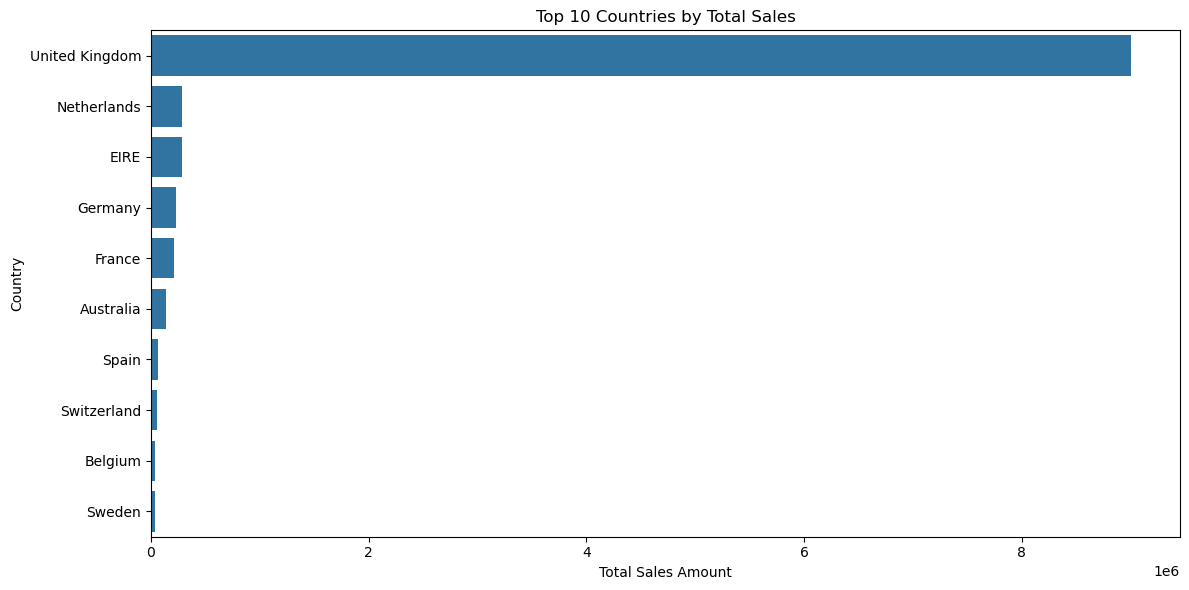

In [14]:

# ==========================================
# سلول ۱۱: شناسایی بازارهای اصلی
# ==========================================

فروش_کشورها = (
    فروش_پاک.groupby("Country")
    .agg(
        مبلغ_فروش=("SalesAmount", "sum"),
        تعداد_فاکتور=("InvoiceNo", "nunique"),
        تعداد_مشتری=("CustomerID", "nunique")
    )
    .sort_values("مبلغ_فروش", ascending=False)
)

print("۱۰ کشور برتر از نظر مجموع مبلغ فروش:")
display(فروش_کشورها.head(10).round(2))

ده_کشور = فروش_کشورها.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ده_کشور,
    x="مبلغ_فروش",
    y="Country"
)

plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales Amount")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


,Description,تعداد_فروخته_شده,مبلغ_فروش,تعداد_فاکتور
0,DOTCOM POSTAGE,706,206248.77,706
1,REGENCY CAKESTAND 3 TIER,13851,174156.54,1988
2,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
3,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72,2256
4,PARTY BUNTING,18283,99445.23,1685
5,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
6,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
7,POSTAGE,3150,78101.88,1126
8,Manual,6985,77752.82,290
9,RABBIT NIGHT LIGHT,30739,66870.03,994


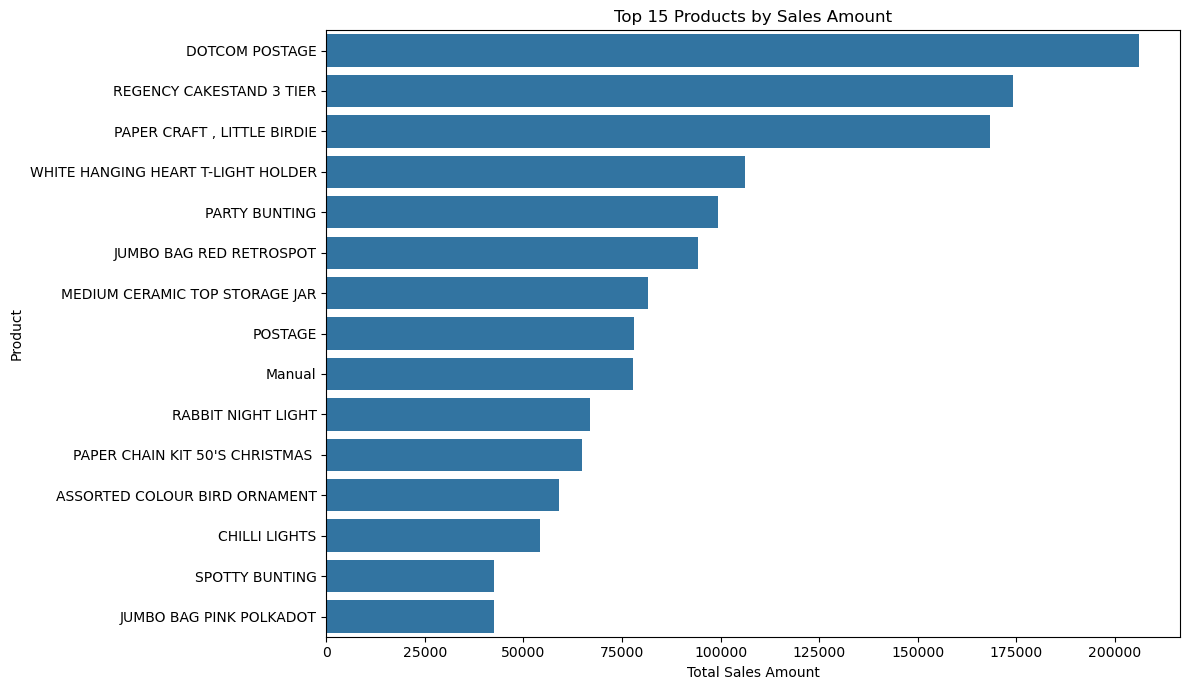

In [15]:

# ==========================================
# سلول ۱۲: تحلیل محصولات پرفروش
# ==========================================

فروش_محصولات = فروش_پاک.copy()

فروش_محصولات["Description"] = (
    فروش_محصولات["Description"].fillna("نامشخص")
)

محصولات_برتر = (
    فروش_محصولات.groupby("Description")
    .agg(
        تعداد_فروخته_شده=("Quantity", "sum"),
        مبلغ_فروش=("SalesAmount", "sum"),
        تعداد_فاکتور=("InvoiceNo", "nunique")
    )
    .sort_values("مبلغ_فروش", ascending=False)
    .head(15)
    .reset_index()
)

display(محصولات_برتر.round(2))

plt.figure(figsize=(12, 7))

sns.barplot(
    data=محصولات_برتر,
    x="مبلغ_فروش",
    y="Description"
)

plt.title("Top 15 Products by Sales Amount")
plt.xlabel("Total Sales Amount")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


In [16]:

# ==========================================
# سلول ۱۳: تحلیل رفتار مشتریان
# ==========================================

فروش_مشتریان = فروش_پاک.dropna(subset=["CustomerID"]).copy()

خلاصه_مشتریان = (
    فروش_مشتریان.groupby("CustomerID")
    .agg(
        مجموع_خرید=("SalesAmount", "sum"),
        تعداد_فاکتور=("InvoiceNo", "nunique"),
        تعداد_واحد_خرید=("Quantity", "sum"),
        اولین_خرید=("InvoiceDate", "min"),
        آخرین_خرید=("InvoiceDate", "max")
    )
)

خلاصه_مشتریان["میانگین_مبلغ_فاکتور"] = (
    خلاصه_مشتریان["مجموع_خرید"]
    / خلاصه_مشتریان["تعداد_فاکتور"]
)

print("تعداد مشتریان قابل تحلیل:", len(خلاصه_مشتریان))

print("\n۱۰ مشتری برتر از نظر مجموع خرید:")
display(
    خلاصه_مشتریان.sort_values(
        "مجموع_خرید", ascending=False
    ).head(10).round(2)
)

print("\nخلاصه آماری رفتار مشتریان:")
display(
    خلاصه_مشتریان[
        ["مجموع_خرید", "تعداد_فاکتور", "تعداد_واحد_خرید",
         "میانگین_مبلغ_فاکتور"]
    ].describe().T.round(2)
)


تعداد مشتریان قابل تحلیل: 4338

۱۰ مشتری برتر از نظر مجموع خرید:


,مجموع_خرید,تعداد_فاکتور,تعداد_واحد_خرید,اولین_خرید,آخرین_خرید,میانگین_مبلغ_فاکتور
CustomerID,,,,,,
14646.0,280206.02,73,196915,2010-12-20 10:09:00,2011-12-08 12:12:00,3838.44
18102.0,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,4327.62
17450.0,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,4225.89
16446.0,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,84236.25
14911.0,143711.17,201,80240,2010-12-01 14:05:00,2011-12-08 15:54:00,714.98
12415.0,124914.53,21,77374,2011-01-06 11:12:00,2011-11-15 14:22:00,5948.31
14156.0,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00,2131.09
17511.0,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,2937.50
16029.0,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00,1283.35



خلاصه آماری رفتار مشتریان:


,count,mean,std,min,25%,50%,75%,max
مجموع_خرید,4338.0,2048.69,8985.23,3.75,306.48,668.57,1660.60,280206.02
تعداد_فاکتور,4338.0,4.27,7.70,1.00,1.00,2.00,5.00,209.00
تعداد_واحد_خرید,4338.0,1187.64,5043.62,1.00,159.00,378.00,989.75,196915.00
میانگین_مبلغ_فاکتور,4338.0,417.65,1796.51,3.45,177.87,291.94,428.28,84236.25


تعداد فاکتورهای معتبر: 19960

آمار توصیفی مبلغ فاکتورها:


,آمار مبلغ فاکتور
count,19960.00
mean,533.17
std,1780.41
min,0.38
25%,151.70
50%,303.30
75%,493.46
max,168469.60


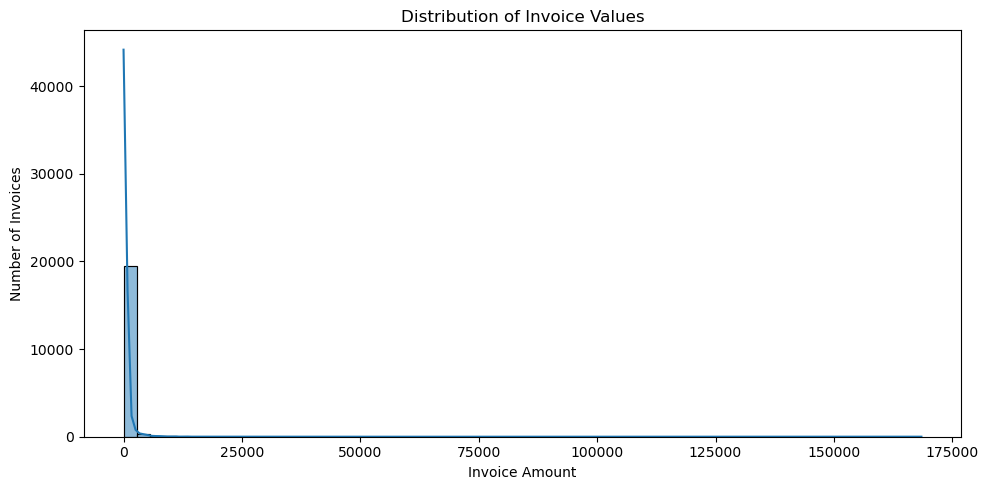

In [17]:

# ==========================================
# سلول ۱۴: ساخت جدول سطح فاکتور
# ==========================================

فاکتورها = (
    فروش_پاک.groupby("InvoiceNo")
    .agg(
        مبلغ_فاکتور=("SalesAmount", "sum"),
        تعداد_اقلام=("Quantity", "sum"),
        تعداد_ردیف_کالا=("StockCode", "size"),
        تاریخ_فاکتور=("InvoiceDate", "min"),
        شناسه_مشتری=("CustomerID", "first"),
        کشور=("Country", "first")
    )
    .reset_index()
)

print("تعداد فاکتورهای معتبر:", len(فاکتورها))

print("\nآمار توصیفی مبلغ فاکتورها:")
display(
    فاکتورها["مبلغ_فاکتور"]
    .describe()
    .to_frame("آمار مبلغ فاکتور")
    .round(2)
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=فاکتورها,
    x="مبلغ_فاکتور",
    bins=60,
    kde=True
)

plt.title("Distribution of Invoice Values")
plt.xlabel("Invoice Amount")
plt.ylabel("Number of Invoices")
plt.tight_layout()
plt.show()


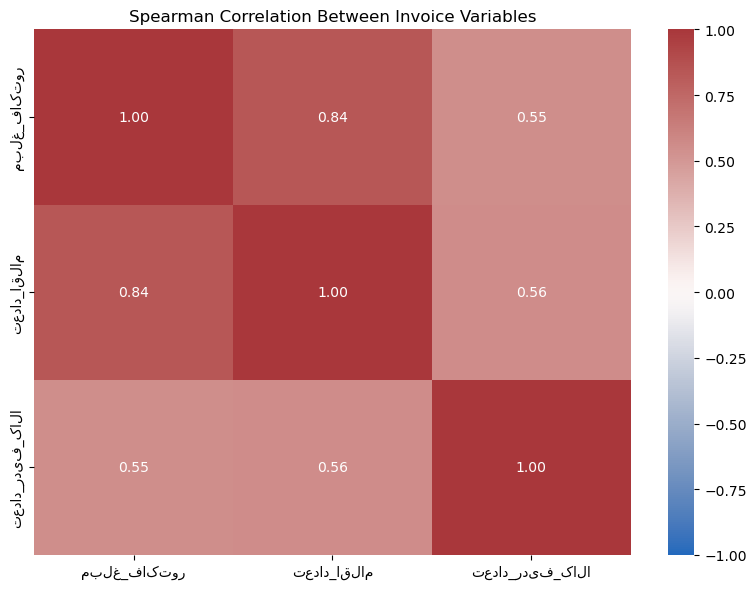

,مبلغ_فاکتور,تعداد_اقلام,تعداد_ردیف_کالا
مبلغ_فاکتور,1.000,0.839,0.552
تعداد_اقلام,0.839,1.000,0.557
تعداد_ردیف_کالا,0.552,0.557,1.000


In [18]:

# ==========================================
# سلول ۱۵: ماتریس همبستگی در سطح فاکتور
# ==========================================

متغیرهای_فاکتور = [
    "مبلغ_فاکتور",
    "تعداد_اقلام",
    "تعداد_ردیف_کالا"
]

ماتریس_همبستگی_فاکتور = فاکتورها[
    متغیرهای_فاکتور
].corr(method="spearman")

plt.figure(figsize=(8, 6))

sns.heatmap(
    ماتریس_همبستگی_فاکتور,
    annot=True,
    cmap="vlag",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Spearman Correlation Between Invoice Variables")
plt.tight_layout()
plt.show()

display(ماتریس_همبستگی_فاکتور.round(3))


In [19]:

# ==========================================
# سلول ۱۶: گزارش مدیریتی خلاصه فروش
# ==========================================

تعداد_فاکتور = فاکتورها["InvoiceNo"].nunique()
تعداد_مشتری = فروش_مشتریان["CustomerID"].nunique()
مجموع_فروش = فروش_پاک["SalesAmount"].sum()
میانگین_فاکتور = فاکتورها["مبلغ_فاکتور"].mean()
میانه_فاکتور = فاکتورها["مبلغ_فاکتور"].median()

بهترین_کشور = فروش_کشورها.index[0]
بهترین_محصول = محصولات_برتر.iloc[0]["Description"]

print("=" * 60)
print("گزارش مدیریتی تحلیل فروش فروشگاه آنلاین")
print("=" * 60)

print(f"تعداد ردیف‌های فروش معتبر: {len(فروش_پاک):,}")
print(f"تعداد فاکتورهای معتبر: {تعداد_فاکتور:,}")
print(f"تعداد مشتریان دارای شناسه: {تعداد_مشتری:,}")
print(f"مجموع مبلغ ردیف‌های فروش: {مجموع_فروش:,.2f}")
print(f"میانگین مبلغ فاکتور: {میانگین_فاکتور:,.2f}")
print(f"میانه مبلغ فاکتور: {میانه_فاکتور:,.2f}")
print(f"کشور با بیشترین مبلغ فروش: {بهترین_کشور}")
print(f"محصول با بیشترین مبلغ فروش: {بهترین_محصول}")

print("=" * 60)
print("توجه: نتایج بر اساس تراکنش‌های مثبت و فاکتورهای غیرلغوشده است.")


گزارش مدیریتی تحلیل فروش فروشگاه آنلاین
تعداد ردیف‌های فروش معتبر: 524,878
تعداد فاکتورهای معتبر: 19,960
تعداد مشتریان دارای شناسه: 4,338
مجموع مبلغ ردیف‌های فروش: 10,642,110.80
میانگین مبلغ فاکتور: 533.17
میانه مبلغ فاکتور: 303.30
کشور با بیشترین مبلغ فروش: United Kingdom
محصول با بیشترین مبلغ فروش: DOTCOM POSTAGE
توجه: نتایج بر اساس تراکنش‌های مثبت و فاکتورهای غیرلغوشده است.


In [20]:

# ==========================================
# سلول ۱۷: ذخیره جداول تحلیلی
# ==========================================

مسیر_خروجی = r"C:\Users\EMTOO\Downloads"

فروش_پاک.to_csv(
    os.path.join(مسیر_خروجی, "cleaned_online_retail.csv"),
    index=False,
    encoding="utf-8-sig"
)

فروش_ماهانه.to_csv(
    os.path.join(مسیر_خروجی, "monthly_sales_analysis.csv"),
    index=False,
    encoding="utf-8-sig"
)

خلاصه_مشتریان.to_csv(
    os.path.join(مسیر_خروجی, "customer_analysis.csv"),
    encoding="utf-8-sig"
)

فاکتورها.to_csv(
    os.path.join(مسیر_خروجی, "invoice_analysis.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("فایل‌های خروجی با موفقیت ذخیره شدند.")
print("مسیر ذخیره‌سازی:", مسیر_خروجی)


فایل‌های خروجی با موفقیت ذخیره شدند.
مسیر ذخیره‌سازی: C:\Users\EMTOO\Downloads


In [21]:

# ==========================================
# سلول ۱۸: ابزارهای یادگیری ماشین
# ==========================================

 

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("ابزارهای Scikit-learn آماده هستند.")


ابزارهای Scikit-learn آماده هستند.


In [22]:

# ==========================================
# سلول ۱۹: ساخت ویژگی‌های RFM
# ==========================================

داده_RFM = فروش_پاک.dropna(
    subset=["CustomerID", "InvoiceDate"]
).copy()

تاریخ_مبنا = داده_RFM["InvoiceDate"].max() + pd.Timedelta(days=1)

RFM = (
    داده_RFM.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (تاریخ_مبنا - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("SalesAmount", "sum")
    )
    .reset_index()
)

print("تعداد مشتریان قابل تحلیل:", len(RFM))
display(RFM.head())
display(RFM[["Recency", "Frequency", "Monetary"]].describe().round(2))


تعداد مشتریان قابل تحلیل: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


,تعداد خوشه,Silhouette Score,Inertia
0,2,0.406,6874.932
1,3,0.416,4299.067
2,4,0.380,3243.033
3,5,0.343,2760.794
4,6,0.330,2396.855


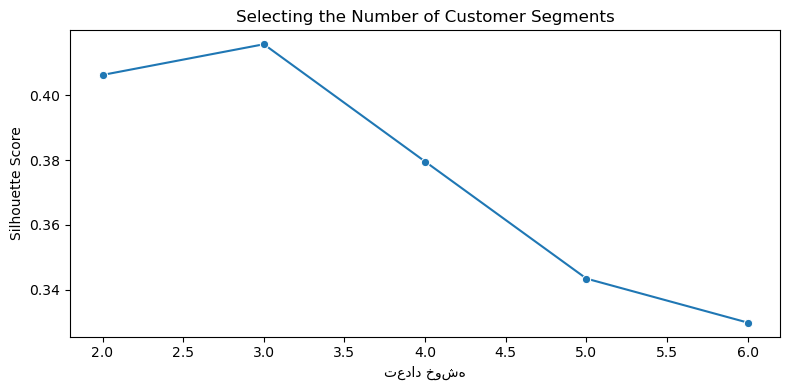

In [24]:

# ==========================================
# سلول ۲۰: آماده‌سازی ویژگی‌ها و ارزیابی K
# ==========================================

# وارد کردن کتابخانه‌های موردنیاز

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

 

ویژگیها = ["Recency", "Frequency", "Monetary"]

X = RFM[ویژگیها].copy()

X["Frequency"] = np.log1p(X["Frequency"])
X["Monetary"] = np.log1p(X["Monetary"])

مقیاس_ساز = StandardScaler()
X_scaled = مقیاس_ساز.fit_transform(X)

نتایج_K = []

for k in range(2, 7):
    مدل = KMeans(n_clusters=k, random_state=42, n_init=10)
    برچسب = مدل.fit_predict(X_scaled)

    نتایج_K.append({
        "تعداد خوشه": k,
        "Silhouette Score": silhouette_score(X_scaled, برچسب),
        "Inertia": مدل.inertia_
    })

نتایج_K = pd.DataFrame(نتایج_K)
display(نتایج_K.round(3))

plt.figure(figsize=(8, 4))
sns.lineplot(
    data=نتایج_K,
    x="تعداد خوشه",
    y="Silhouette Score",
    marker="o"
)
plt.title("Selecting the Number of Customer Segments")
plt.tight_layout()
plt.show()


In [25]:

# ==========================================
# سلول ۲۱: اجرای نهایی مدل K-Means
# ==========================================

بهترین_K = int(
    نتایج_K.loc[
        نتایج_K["Silhouette Score"].idxmax(),
        "تعداد خوشه"
    ]
)

مدل_KMeans = KMeans(
    n_clusters=بهترین_K,
    random_state=42,
    n_init=10
)

RFM["Cluster"] = مدل_KMeans.fit_predict(X_scaled)

print("تعداد خوشه انتخاب‌شده:", بهترین_K)
print("امتیاز Silhouette:",
      round(نتایج_K["Silhouette Score"].max(), 3))

print("\nتعداد مشتریان در هر خوشه:")
display(RFM["Cluster"].value_counts().sort_index().to_frame("تعداد مشتریان"))


تعداد خوشه انتخاب‌شده: 3
امتیاز Silhouette: 0.416

تعداد مشتریان در هر خوشه:


,تعداد مشتریان
Cluster,
0,1320
1,981
2,2037


In [26]:

# ==========================================
# سلول ۲۲: پروفایل آماری خوشه‌های مشتریان
# ==========================================

پروفایل_خوشه = RFM.groupby("Cluster").agg(
    تعداد_مشتری=("CustomerID", "count"),
    میانه_روز_از_آخرین_خرید=("Recency", "median"),
    میانه_تعداد_فاکتور=("Frequency", "median"),
    میانه_مبلغ_خرید=("Monetary", "median"),
    میانگین_مبلغ_خرید=("Monetary", "mean")
).round(2)

display(پروفایل_خوشه)


,تعداد_مشتری,میانه_روز_از_آخرین_خرید,میانه_تعداد_فاکتور,میانه_مبلغ_خرید,میانگین_مبلغ_خرید
Cluster,,,,,
0,1320,17.0,7.0,2570.50,5492.04
1,981,253.0,1.0,290.51,397.17
2,2037,45.0,2.0,508.80,612.71


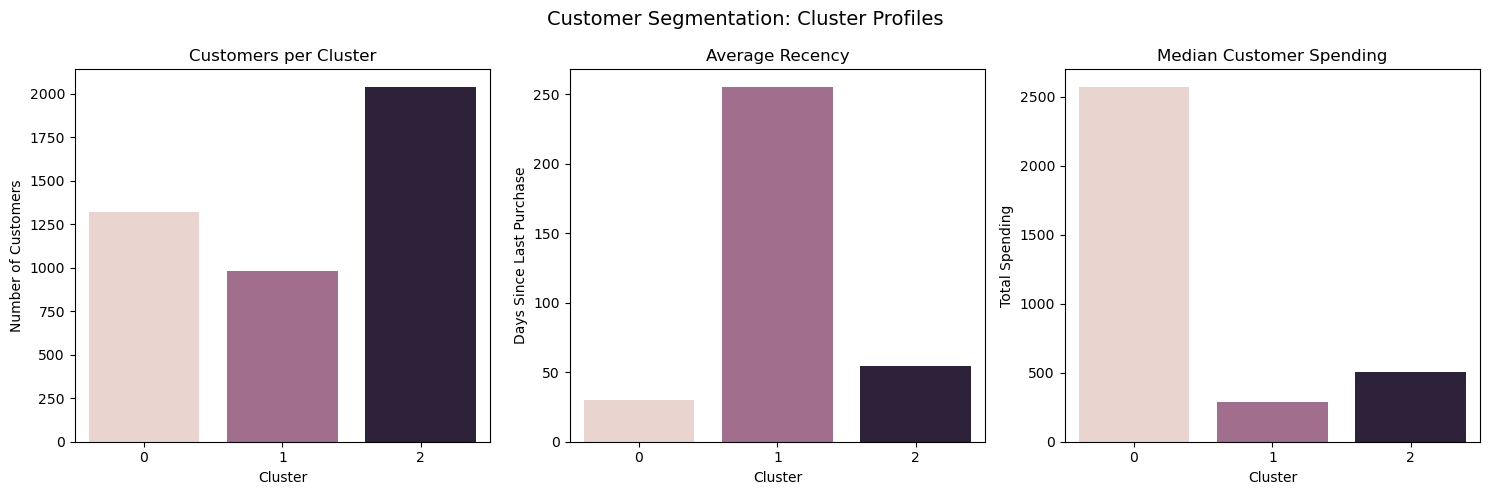

,Cluster,تعداد_مشتری,میانگین_روز_از_آخرین_خرید,میانه_تعداد_فاکتور,میانه_مبلغ_خرید
0,0,1320,30.10,7.0,2570.50
1,1,981,255.11,1.0,290.51
2,2,2037,54.70,2.0,508.80


In [28]:

# ==========================================
# سلول ۲۳: نمایش حرفه‌ای پروفایل خوشه‌های مشتریان
# ==========================================

پروفایل = RFM.groupby("Cluster").agg(
    تعداد_مشتری=("CustomerID", "count"),
    میانگین_روز_از_آخرین_خرید=("Recency", "mean"),
    میانه_تعداد_فاکتور=("Frequency", "median"),
    میانه_مبلغ_خرید=("Monetary", "median")
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.barplot(
    data=پروفایل, x="Cluster", y="تعداد_مشتری",
    hue="Cluster", legend=False, ax=axes[0]
)
axes[0].set_title("Customers per Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Number of Customers")

sns.barplot(
    data=پروفایل, x="Cluster",
    y="میانگین_روز_از_آخرین_خرید",
    hue="Cluster", legend=False, ax=axes[1]
)
axes[1].set_title("Average Recency")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Days Since Last Purchase")

sns.barplot(
    data=پروفایل, x="Cluster",
    y="میانه_مبلغ_خرید",
    hue="Cluster", legend=False, ax=axes[2]
)
axes[2].set_title("Median Customer Spending")
axes[2].set_xlabel("Cluster")
axes[2].set_ylabel("Total Spending")

plt.suptitle("Customer Segmentation: Cluster Profiles", fontsize=14)
plt.tight_layout()
plt.show()

display(پروفایل.round(2))
